In [1]:
import sys,os
sys.path.append('../../')
os.environ["JAX_PLATFORMS"] = "cpu"
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder,get_acronym,depths
from ranks import (reduce_list_half_preserve_extremes,
                   )
from geometry import * 

eps = 1E-7
rcpsize = 12
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['p','o','h','^','s','*']
_linestyles = ['-','--','dotted']
plot_id = 0

2025-06-25 13:32:25


### ranks

Nbits=0
II_fn(x_ranks,y_ranks)=(Array(0.94247247, dtype=float64), Array(0.83854655, dtype=float64))
A_fn(x_ranks,y_ranks)=(Array(0.0214, dtype=float64), Array(0.92846246, dtype=float64), Array(0.90442723, dtype=float64))
Nbits=1
II_fn(x_ranks,y_ranks)=(Array(0.93315848, dtype=float64), Array(0.88108108, dtype=float64))
A_fn(x_ranks,y_ranks)=(Array(0.01809524, dtype=float64), Array(0.94901037, dtype=float64), Array(0.92499037, dtype=float64))


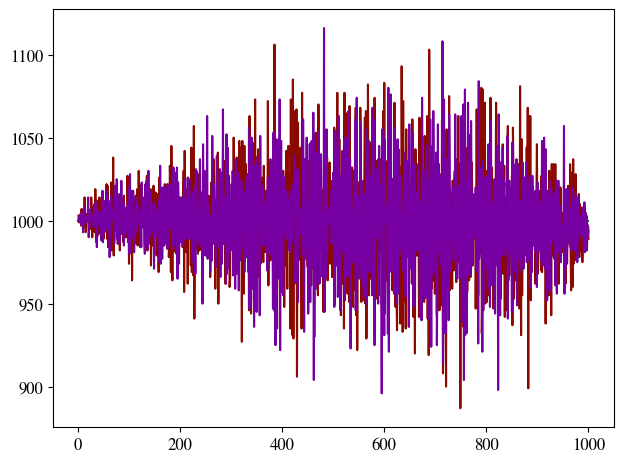

In [4]:
# modelA = 'deepseek'
modelA = 'llama'
modelB = modelA
mask = 2
language_pairs = [('english','spanish'),
                  ]
aux_A = 'source'
aux_B = 'target'

min_token_length = 40
n_files = 200
batch_size = 10 
Ns = batch_size*n_files
n_tokens_list = [20]
avg = 0
Nbits_list = [0,1]

layer_A = 1
layer_B = 1 

fig,ax = plt.subplots(1)

idx = None
for Nbits_id,Nbits in enumerate(Nbits_list):
  print(f'{Nbits=}')
  for language_pair_id, language_pair in enumerate(language_pairs):
    for n_tokens in n_tokens_list:
      (languageA,languageB) = language_pair
      output_folder0 = makefolder(base=f'./results/',
                                    create_folder=False,
                                    modelA=modelA,
                                    modelB=modelB,
                                    aux_A=aux_A,
                                    aux_B=aux_B,
                                    n_files=n_files,
                                    min_token_length=min_token_length,
                                    languageA=languageA,
                                    languageB=languageB,
                                    mask=mask,
                                    )
      ranks_folder = makefolder(base=output_folder0+'ranks/',
                                Nbits=Nbits,
                                n_tokens=n_tokens,
                                avg_tokens=avg,
                                layer_A=layer_A,
                                layer_B=layer_B,
                                )
      x_ranks, y_ranks = np.load(ranks_folder+"ranks.npz").values()
      # shuffled_indices = np.random.permutation(x_ranks.shape[0])
      # y_ranks = y_ranks[shuffled_indices]
      II_fn = build_information_imbalance(k=1)
      A_fn = build_mutual_k_NN_alignment(k=10)
      print(f'{II_fn(x_ranks,y_ranks)=}')
      v,c = np.unique(x_ranks[:idx,:],return_counts=True)
      ax.plot(v,c)
      v,c = np.unique(y_ranks[:idx,:],return_counts=True)
      ax.plot(v,c)
      print(f'{A_fn(x_ranks,y_ranks)=}')
# ax.set_yscale('log')
plt.show()

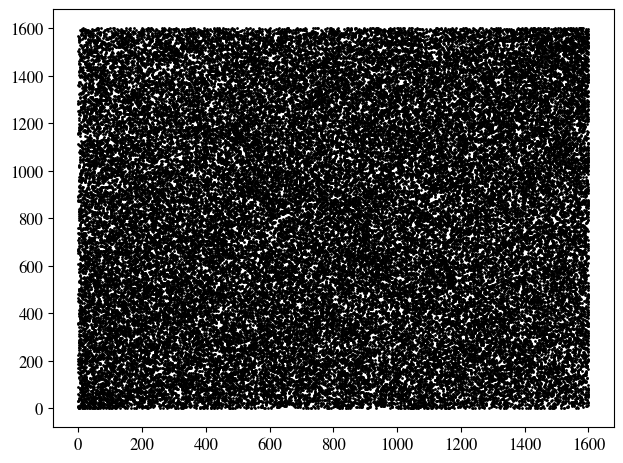

In [9]:
# for i in range(0,len(x_ranks),8):
plt.scatter(x_ranks[::10],y_ranks[::10],color='black',s=1)

### II

Text(0.5, 1.0, 'llama')

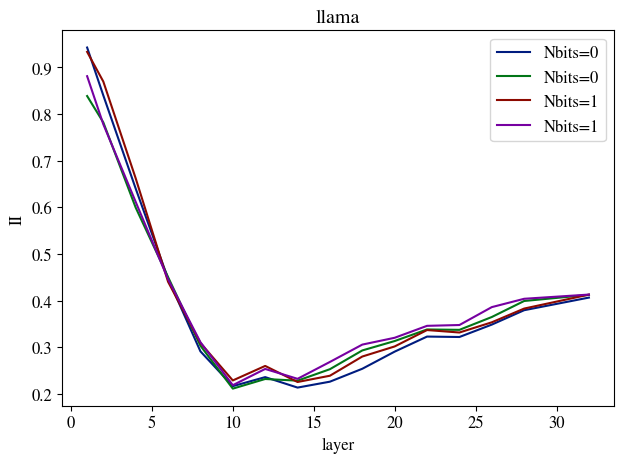

In [5]:
fig,ax = plt.subplots(1)
for Nbits_id,Nbits in enumerate(Nbits_list):
  for language_pair_id, language_pair in enumerate(language_pairs):
    for n_tokens in n_tokens_list:
      (languageA,languageB) = language_pair
      output_folder0 = makefolder(base=f'./results/',
                                    create_folder=False,
                                    modelA=modelA,
                                    modelB=modelB,
                                    aux_A=aux_A,
                                    aux_B=aux_B,
                                    n_files=n_files,
                                    min_token_length=min_token_length,
                                    languageA=languageA,
                                    languageB=languageB,
                                    mask=mask,
                                    )
      II_folder = makefolder(base=output_folder0,
                                        create_folder=False,
                                        Nbits=Nbits,
                                        n_tokens=n_tokens,
                                        avg_tokens=avg,
                                        )
      IIs = np.load(II_folder+"IIs.npy")

      layers_A = list(range(1,depths[modelA] + 1))
      layers_B = list(range(1,depths[modelB] + 1))

      layers = reduce_list_half_preserve_extremes(layers_A)
          
      for II_index in range(2):
        plt.plot(layers,IIs[II_index].diagonal(),label=f'{Nbits=}')

ax.legend()
ax.set_xlabel('layer')
ax.set_ylabel('II')
ax.set_title(f'{modelA}')